# 03 · XGBoost baseline: results

This notebook reviews the trained XGBoost severity classifier using the artifacts
committed in `ml/artifacts/`. It does not retrain the model: training needs the
DrugBank, DailyMed and FAERS datasets, which are not in the repo
(see `ml/training/train_xgboost.py`).

**Task.** Classify a drug pair into one of four severity classes:
0 = none, 1 = minor, 2 = moderate, 3 = major.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
ARTIFACTS = ROOT / "ml" / "artifacts"

## Tuned hyperparameters

Found with an Optuna search (`train_xgboost.py --tune`).

In [2]:
params = json.loads((ARTIFACTS / "xgb_best_params.json").read_text())
pd.Series(params, name="value").to_frame()

,value
max_depth,10
learning_rate,0.054074
subsample,0.602918
colsample_bytree,0.612205
min_child_weight,3
gamma,0.136584
reg_alpha,0.979264
reg_lambda,0.972972
n_estimators,887
objective,multi:softprob


## Headline metrics

In [3]:
comparison = json.loads((ARTIFACTS / "eval" / "model_comparison.json").read_text())
metrics = pd.DataFrame({k: v for k, v in comparison.items() if isinstance(v, dict)}).T
metrics

,accuracy,macro_f1,macro_auc,auc,severity_mae
xgboost,0.998523,0.428325,0.991161,NaN,NaN
gnn,0.999855,0.549964,NaN,0.942726,0.414903


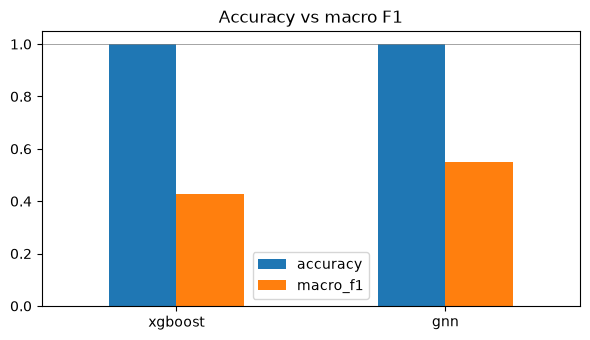

In [4]:
ax = metrics[["accuracy", "macro_f1"]].plot.bar(figsize=(6, 3.5), rot=0)
ax.set_ylim(0, 1.05)
ax.set_title("Accuracy vs macro F1")
ax.axhline(1.0, color="grey", lw=0.5)
plt.tight_layout()

**Reading the numbers.** Accuracy is above 99.8% but macro F1 is about 0.43.
The dataset is heavily imbalanced: most drug pairs have no recorded interaction,
so a model can score high accuracy by mostly predicting "none". Macro F1 weights
each severity class equally and shows the minority classes (the dangerous ones)
are much harder. Macro AUC of 0.99 says the model ranks pairs well, so threshold
tuning and class reweighting are the obvious next steps.

## What drives predictions (mean |SHAP|)

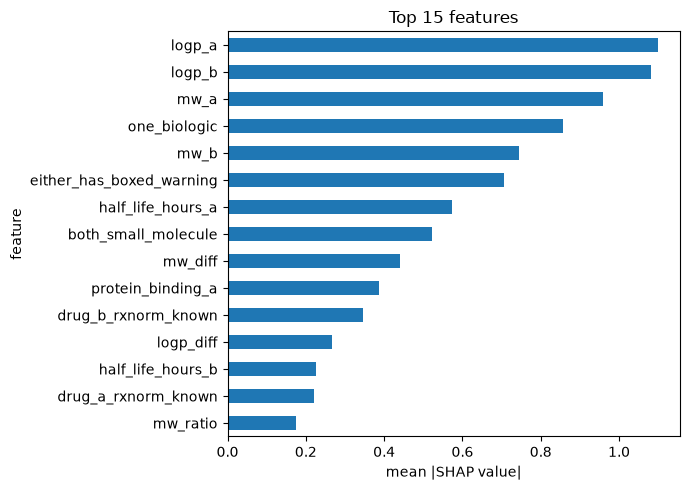

In [5]:
shap = pd.read_csv(ARTIFACTS / "xgb_shap_importance.csv").sort_values("importance")
ax = shap.tail(15).plot.barh(x="feature", y="importance", figsize=(7, 5), legend=False)
ax.set_xlabel("mean |SHAP value|")
ax.set_title("Top 15 features")
plt.tight_layout()

Lipophilicity (logP), molecular weight and half-life rank highest, along with
whether either drug carries an FDA boxed warning. These are plausible
pharmacokinetic signals, but they also describe the drugs individually rather
than the pair, which suggests the model partly learns which drugs are "risky"
in general. Pair-level features such as the CYP450 inhibitor/substrate overlap
(`ml/features/cyp450_features.py`) are where to look for further gains.

## Limitations
- Labels come from curated databases, so absent interactions are not proven safe.
- Imbalance means accuracy is not a useful headline metric for this task.
- This is a research prototype, not a clinical decision tool.